# 필요 SNR T — 판정·방향이 몇 dB에서 무너지나 (Step8d)

> 2026-10-28 작성 · 녹음 도구 [`board/stream_capture.py`](../board/stream_capture.py) · 방향 PC 기준 구현 [`doa/doa_stream.py`](../doa/doa_stream.py) · B0 [`harmonic/score.py`](../harmonic/score.py) · 커널: `Tools/.venv`
> 결론은 마지막 절에 **결론 후보**로만 적는다. 사용자가 확인한 뒤 Step8d 결과·결정으로 올린다.

**질문:** 드론 소리를 2 dB씩 줄여 가며 틀 때, B0 판정과 방향이 성공하는 비율이 50 %·90 %가 되는 SNR은 몇 dB인가? 이 값이 탐지거리 식 r = 10^((L₁ − N − T) ÷ 20)의 **T**다.

| 조건 | 값 |
|---|---|
| 재생 파일 | `DataSet/_playback/51_T_fpv_steps.wav` (FPV) 또는 `52_T_mini3_steps.wav` — 20 s 조용히 → 0 dB부터 −40 dB까지 2 dB씩 21단계 × 30 s → 20 s 조용히 (670 s) |
| 보드 녹음 | `Tools/dumps/stream/T_fpv/` · `T_mini3/` (12.5 kHz · 3채널 · int16), 트리머는 보드 눈금(`spl_cal`) 때와 같음 |
| SNR (측정 전 고정, Step8d) | ch1의 300 ~ 3000 Hz 대역에서 (창 전력 − 바닥 전력) ÷ 바닥 전력, dB. 바닥 = 재생 전 조용한 구간. 창마다 재고 2 dB 칸으로 묶는다 |
| B0 성공 | 1 s 창의 B0 점수(40 ~ 700 Hz) ≥ 13.1 (Step8b 문턱). 조용한 창 규칙은 끈다 |
| 방향 성공 | 보드 결과(`doa_mcu.csv`)가 유효(VALID)·소리 있음(PRESENT)이고, 높은 SNR 구간(0 ~ −4 dB 단계)의 방위 중앙값과 ±10° 안 |
| 통과 기준 | 50 %·90 % SNR을 각각 ±2 dB 안으로 (2.5 ~ 97.5 % 구간의 절반 폭 ≤ 2 dB) |

**한계**
- 소리는 노트북 스피커로 0.5 m에서 튼 것이다. 실제 비행체의 거리·바람·지면 반사는 없다. 잡음은 조용한 방의 바닥이라, 바람·교통 소음 아래에서의 T는 다를 수 있다 (Step8d 가정).
- 단계 경계 앞뒤 1 s 창은 뺀다. 재생 PC와 보드의 시계 차이(약 50 ppm → 670 s에 약 34 ms)는 무시한다.
- **아래 `REC` 폴더가 없으면 리허설 모드로 돈다:** 실제 장치 녹음 두 개(`quiet_10min` 바닥 + `doa_az000`의 FPV 60 s, 왼쪽 스피커 1 m, 정답 0°)를 섞어 단계 입력을 만든다. 흐름 확인용이며 **리허설 숫자는 T가 아니다.** 방향은 보드 결과 대신 PC 기준 구현으로 계산한다.

In [1]:
import os, sys, json, csv, argparse
import numpy as np
import soundfile as sf
import matplotlib.pyplot as plt
from matplotlib import font_manager
from scipy.signal import butter, sosfiltfilt, welch
_have = {f.name for f in font_manager.fontManager.ttflist}
plt.rcParams["font.family"] = next((f for f in ("Malgun Gothic", "AppleGothic", "NanumGothic") if f in _have), "sans-serif")
plt.rcParams["axes.unicode_minus"] = False
sys.path[:0] = [os.path.abspath(".."), os.path.abspath("../doa")]
import harmonic.score as hs
import doa_stream as ds

LABEL, PLAYBACK = "T_fpv", "51_T_fpv_steps.wav"        # Mini 3 Pro는 "T_mini3", "52_T_mini3_steps.wav"
REC = f"../dumps/stream/{LABEL}"
PB = f"../../DataSet/_playback/{PLAYBACK}"
FS = 12500
LEAD, STEP_S, N_STEP = 20.0, 30.0, 21                 # 재생 파일 구조
B0_CANDS, B0_THR = [hs.candidates(40, 700)], 13.1
DOA_TOL = 10.0
SOS = butter(4, [300, 3000], btype="band", fs=FS, output="sos")
F_VALID, F_PRESENT, F_LEARN = 0x01, 0x02, 0x08
MODE = "실측" if os.path.isdir(REC) else "리허설"
print(f"모드: {MODE}  ({REC})")

모드: 리허설  (../dumps/stream/T_fpv)


## 1. 녹음 불러오기

실측이면 보드 녹음의 가장 긴 연속 구간과 무결성 판정(`summary.json`)을 본다. 리허설이면 아래 셀이 단계 입력을 만든다: `quiet_10min`을 720 s로 이어 붙이고, 15 s부터 재생 파일과 같은 일정으로 FPV 60 s의 앞·뒤 30 s를 번갈아 2 dB씩 줄여 더한다.

**그림에서 볼 것:** ch1 대역 크기가 계단처럼 2 dB씩 내려가다 바닥(실측이면 약 −64 dBFS 근처, 보드 눈금 녹음 기준)에 닿는 모양.

리허설 입력 720 s, 넣은 재생 시작 15.0 s


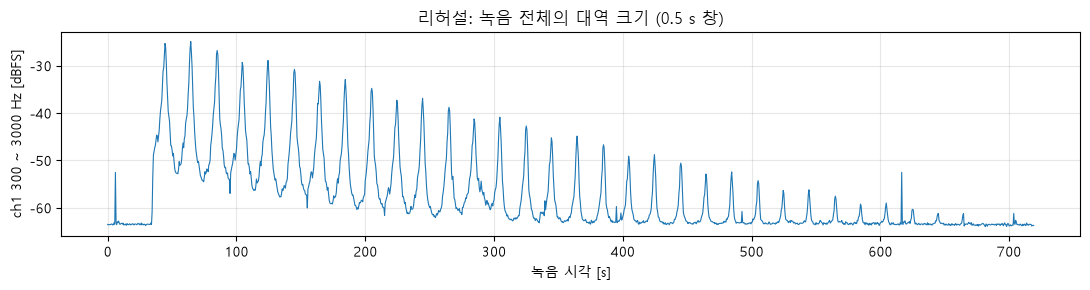

In [2]:
if MODE == "실측":
    X, START = ds.load_folder(REC)
    S = json.load(open(f"{REC}/summary.json", encoding="utf-8"))
    print("무결성:", S["criteria"], "통과" if S["passed"] else "실패", f"· 연속 구간 {X.shape[1] / FS:.1f} s")
else:
    q, _ = ds.load_folder("../dumps/stream/quiet_10min")
    az, _ = ds.load_folder("../dumps/stream/doa_az000")
    clip = az[:, int(1.5 * FS):int(61.5 * FS)]        # doa_az000 재생 시작 1.5 s (21_doa_left와 상관 0.98), 앞 60 s = FPV 3개
    n = int(720 * FS); P0_TRUE = 15.0
    X = np.concatenate([q, q[:, :n - q.shape[1]]], axis=1)[:, :n].copy()
    L = int(STEP_S * FS)
    for k in range(N_STEP):
        a = int((P0_TRUE + LEAD + STEP_S * k) * FS)
        X[:, a:a + L] += 10 ** (-2 * k / 20) * clip[:, (k % 2) * L:(k % 2) * L + L]
    START = 0
    print(f"리허설 입력 {X.shape[1] / FS:.0f} s, 넣은 재생 시작 {P0_TRUE} s")

B1 = sosfiltfilt(SOS, X[0] - X[0].mean())               # ch1 300 ~ 3000 Hz
def env_db(sig, fs, win=0.5, hop=0.5):
    sos = butter(4, [300, 3000], btype="band", fs=fs, output="sos"); b = sosfiltfilt(sos, sig)
    w, h = int(win * fs), int(hop * fs); idx = np.arange(0, len(b) - w, h)
    return np.array([10 * np.log10(2 * np.mean(b[i:i + w] ** 2) + 1e-20) for i in idx]), idx / fs
E_REC, T_REC = env_db(X[0] / 32768, FS)
fig, ax = plt.subplots(figsize=(11, 3))
ax.plot(T_REC, E_REC, lw=.8); ax.set_xlabel("녹음 시각 [s]"); ax.set_ylabel("ch1 300 ~ 3000 Hz [dBFS]"); ax.grid(alpha=.3)
ax.set_title(f"{MODE}: 녹음 전체의 대역 크기 (0.5 s 창)"); plt.tight_layout(); plt.show()

## 2. 재생 시작 찾기

재생은 사람이 손으로 시작하므로 녹음 안 어디서 시작했는지 모른다. 재생 파일과 녹음의 대역 크기(dB) 곡선을 겹쳐 가장 잘 맞는 어긋남을 찾는다. 0.5 s 간격으로 대충 찾은 뒤 ±1 s를 0.05 s 간격으로 다시 찾는다. 바닥 아래는 의미가 없으니 녹음은 바닥 + 3 dB, 재생 파일은 최대 − 40 dB에서 자른다.

**예상:** 리허설은 넣은 값 15.0 s 근처, 실측은 B1을 누른 뒤 12 s 조용히 했으므로 약 12 ~ 20 s.

재생 시작 15.55 s (대략 15.5 s, 상관 0.643) · 넣은 값 15.0 s, 차이 +0.55 s


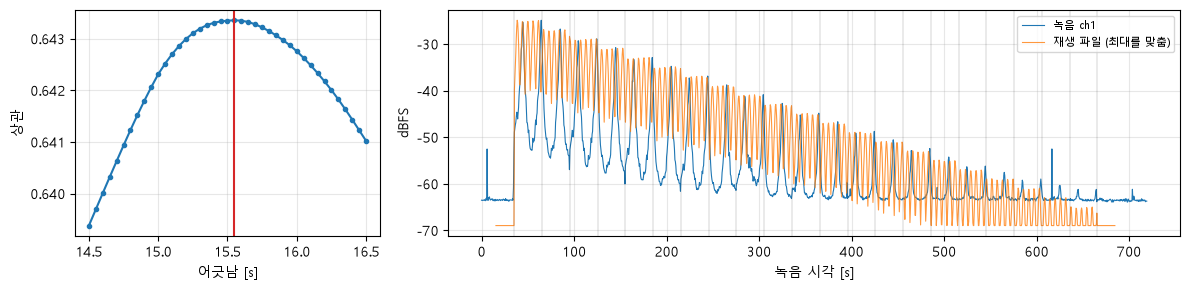

In [3]:
pb, fpb = sf.read(PB, dtype="float64"); pb = pb if pb.ndim == 1 else pb[:, 0]
def best_lag(win, hop, lags):
    e_r, _ = env_db(X[0] / 32768, FS, win, hop); e_p, _ = env_db(pb, fpb, win, hop)
    r = np.maximum(e_r, np.median(e_r[:int(8 / hop)]) + 3); p = np.maximum(e_p, e_p.max() - 40)
    cc = []
    for g in lags:
        i = int(round(g / hop)); seg = r[i:i + len(p)]
        cc.append(np.corrcoef(seg, p[:len(seg)])[0, 1] if len(seg) > 0.9 * len(p) else np.nan)
    return np.array(cc)
lag1 = np.arange(0, 120, 0.5); cc1 = best_lag(0.5, 0.5, lag1); g1 = lag1[np.nanargmax(cc1)]
lag2 = np.arange(max(0, g1 - 1), g1 + 1.0001, 0.05); cc2 = best_lag(0.5, 0.05, lag2); P0 = float(lag2[np.nanargmax(cc2)])
print(f"재생 시작 {P0:.2f} s (대략 {g1:.1f} s, 상관 {np.nanmax(cc2):.3f})" + (f" · 넣은 값 {P0_TRUE} s, 차이 {P0 - P0_TRUE:+.2f} s" if MODE == "리허설" else ""))
e_p, t_p = env_db(pb, fpb)
fig, ax = plt.subplots(1, 2, figsize=(12, 3), gridspec_kw=dict(width_ratios=[1, 2.4]))
ax[0].plot(lag2, cc2, ".-"); ax[0].axvline(P0, color="C3"); ax[0].set_xlabel("어긋남 [s]"); ax[0].set_ylabel("상관"); ax[0].grid(alpha=.3)
ax[1].plot(T_REC, E_REC, lw=.8, label="녹음 ch1"); ax[1].plot(t_p + P0, np.maximum(e_p - e_p.max() + E_REC.max(), E_REC.min() - 5), lw=.8, alpha=.8, label="재생 파일 (최대를 맞춤)")
for k in range(N_STEP + 1): ax[1].axvline(P0 + LEAD + STEP_S * k, color="k", lw=.3, alpha=.4)
ax[1].set_xlabel("녹음 시각 [s]"); ax[1].set_ylabel("dBFS"); ax[1].legend(fontsize=8); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

## 3. 바닥

재생 전 10 s와 재생 파일 앞의 조용한 20 s 중 18 s, 합쳐 28 s를 0.5 s 창으로 잘라 ch1 대역 전력의 중앙값을 바닥으로 쓴다. 바닥 스펙트럼도 같이 본다 — 48.8 Hz(프레임 주기)의 배수 줄이 보이면 B0가 이것을 고조파로 볼 수 있다 (5절).

**예상(손계산):** 보드 눈금 녹음의 조용한 바닥이 ch1 약 −64 dBFS(+K 94.5 → 약 30 dB SPL)였다.

바닥 = -63.5 dBFS (ch1 300 ~ 3000 Hz, 0.5 s 창 56개의 중앙값)


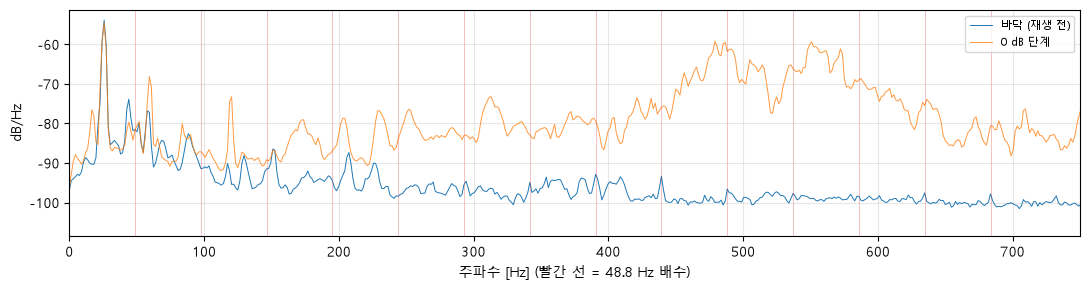

In [4]:
def pw(a, b): return float(np.mean(B1[int(a * FS):int(b * FS)] ** 2))
FL_T = np.arange(P0 - 10, P0 + 18, 0.5)
P_FL = float(np.median([pw(t, t + 0.5) for t in FL_T]))
print(f"바닥 = {10 * np.log10(2 * P_FL / 32768 ** 2):.1f} dBFS (ch1 300 ~ 3000 Hz, 0.5 s 창 {len(FL_T)}개의 중앙값)")
f, Pq = welch(X[0, int((P0 - 10) * FS):int((P0 + 18) * FS)] / 32768, FS, nperseg=8192)
f, Ps = welch(X[0, int((P0 + LEAD + 2) * FS):int((P0 + LEAD + 28) * FS)] / 32768, FS, nperseg=8192)
fig, ax = plt.subplots(figsize=(11, 3))
ax.plot(f, 10 * np.log10(Pq), lw=.7, label="바닥 (재생 전)"); ax.plot(f, 10 * np.log10(Ps), lw=.7, alpha=.8, label="0 dB 단계")
for m in range(1, 15): ax.axvline(48.83 * m, color="C3", lw=.4, alpha=.5)
ax.set_xlim(0, 750); ax.set_xlabel("주파수 [Hz] (빨간 선 = 48.8 Hz 배수)"); ax.set_ylabel("dB/Hz"); ax.legend(fontsize=8); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 4. 창마다 SNR

SNR = 10·log₁₀((창 전력 − 바닥) ÷ 바닥). 창 전력이 바닥보다 작으면 값이 없으므로 −30 dB로 둔다. B0는 1 s 창, 방향은 보드와 같은 0.5 s 창을 쓰고, 각 창은 **자기 구간의 SNR**을 갖는다. 겹치는 창은 서로 독립이 아니므로 B0는 1 s 간격(겹침 없음), 방향은 0.5 s 간격만 쓴다.

**예상:** 단계마다 2 dB씩 내려가야 하지만, FPV 원음 자체가 30 s 안에서 크게 출렁여(통과 비행) 같은 단계 안에서도 SNR이 넓게 퍼진다. 그래서 단계가 아니라 창 SNR로 묶는다.

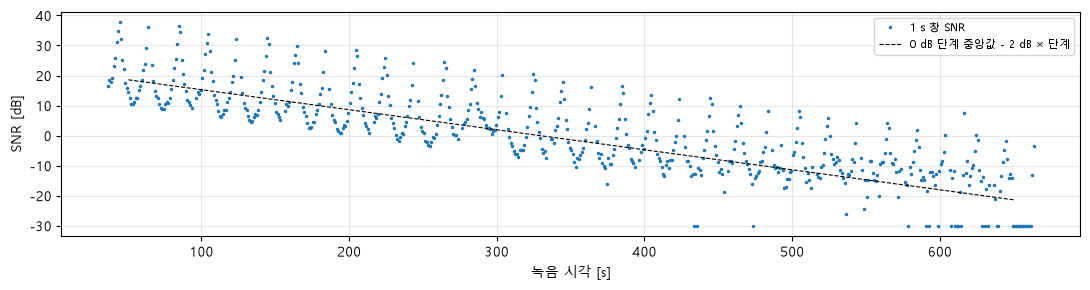

In [5]:
def snr_db(a, b):
    v = pw(a, b) / P_FL - 1.0
    return 10 * np.log10(v) if v > 1e-3 else -30.0
def step_windows(win, hop):
    out = []
    for k in range(N_STEP):
        a0 = P0 + LEAD + STEP_S * k
        for t in np.arange(a0 + 1.0, a0 + STEP_S - 1.0 - win + 1e-9, hop): out.append((k, t))
    return out
BW = step_windows(1.0, 1.0)
B0_K = np.array([k for k, _ in BW]); B0_T = np.array([t for _, t in BW])
B0_SNR = np.array([snr_db(t, t + 1.0) for t in B0_T])
fig, ax = plt.subplots(figsize=(11, 3))
ax.plot(B0_T, B0_SNR, ".", ms=3, label="1 s 창 SNR")
ax.plot(P0 + LEAD + STEP_S * (np.arange(N_STEP) + .5), np.median(B0_SNR[B0_K == 0]) - 2 * np.arange(N_STEP), "k--", lw=.8, label="0 dB 단계 중앙값 - 2 dB × 단계")
ax.set_xlabel("녹음 시각 [s]"); ax.set_ylabel("SNR [dB]"); ax.legend(fontsize=8); ax.grid(alpha=.3); plt.tight_layout(); plt.show()

### 4-1. 한 창 따라가기

10번째 단계(−20 dB)의 첫 창 하나를 손으로 계산한다.

In [6]:
i = int(np.where(B0_K == 10)[0][0]); t = B0_T[i]
pw_w = pw(t, t + 1.0)
s, f0 = hs.score(X[0, int(t * FS):int(t * FS) + FS], B0_CANDS)[0]
print(f"창 시작 {t:.2f} s (단계 10, 재생 −20 dB)")
print(f"  창 전력   = {pw_w:10.1f}  (int16², ch1 대역)")
print(f"  바닥 전력 = {P_FL:10.1f}")
print(f"  SNR = 10·log10(({pw_w:.1f} − {P_FL:.1f}) / {P_FL:.1f}) = {snr_db(t, t + 1.0):.2f} dB")
print(f"  B0 점수 {s:.2f} (기본음 {f0:.0f} Hz) → {'성공' if s >= B0_THR else '실패'} (문턱 {B0_THR})")

창 시작 336.55 s (단계 10, 재생 −20 dB)
  창 전력   =      424.9  (int16², ch1 대역)
  바닥 전력 =      240.5
  SNR = 10·log10((424.9 − 240.5) / 240.5) = -1.15 dB
  B0 점수 12.81 (기본음 601 Hz) → 실패 (문턱 13.1)


## 5. B0 판정

창마다 B0 점수를 내고 13.1과 비교한다. 같은 방식으로 **드론이 없는 창**(재생 전과 재생 파일 앞뒤의 조용한 구간)도 점수를 낸다. 이 비율이 성공률의 바닥이다 — 드론이 들리지 않아도 이만큼은 "성공"으로 세어진다.

**그림에서 볼 것:** 단계가 내려가며 점수가 문턱 아래로 떨어지는 시점, 그리고 조용한 창에서 문턱을 넘는 창의 기본음이 48.8 Hz 근처인지.

조용한 창 46개: B0 ≥ 13.1 비율 0.28 · 넘은 창의 기본음 [46, 45, 46, 46, 40, 50, 45, 42, 52, 45, 44, 44, 48]


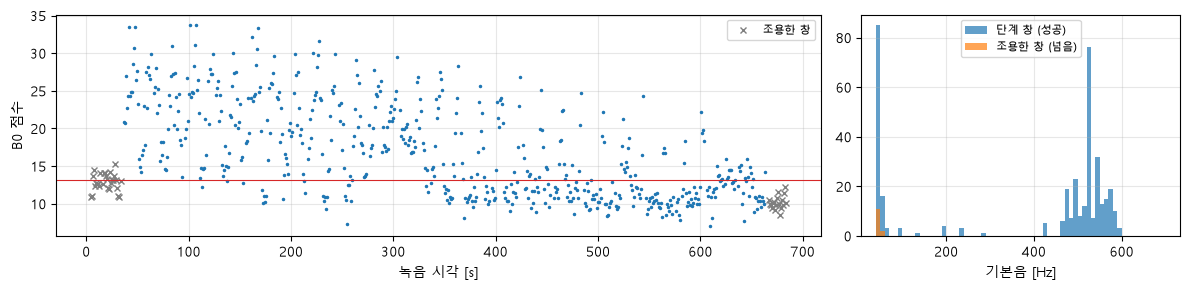

In [7]:
B0_S = np.zeros(len(B0_T)); B0_F = np.zeros(len(B0_T))
for i, t in enumerate(B0_T): B0_S[i], B0_F[i] = hs.score(X[0, int(t * FS):int(t * FS) + FS], B0_CANDS)[0]
B0_OK = B0_S >= B0_THR
QT = np.r_[np.arange(max(1, P0 - 11), P0 - 1, 1.0), np.arange(P0 + 1, P0 + LEAD - 1, 1.0),
           np.arange(P0 + LEAD + STEP_S * N_STEP + 1, min(X.shape[1] / FS - 1, P0 + LEAD + STEP_S * N_STEP + 19), 1.0)]
QS = np.array([hs.score(X[0, int(t * FS):int(t * FS) + FS], B0_CANDS)[0] for t in QT])
Q_RATE = float(np.mean(QS[:, 0] >= B0_THR))
print(f"조용한 창 {len(QT)}개: B0 ≥ {B0_THR} 비율 {Q_RATE:.2f} · 넘은 창의 기본음 {np.round(QS[QS[:, 0] >= B0_THR, 1]).astype(int).tolist()}")
fig, ax = plt.subplots(1, 2, figsize=(12, 3), gridspec_kw=dict(width_ratios=[2.4, 1]))
ax[0].plot(B0_T, B0_S, ".", ms=3); ax[0].plot(QT, QS[:, 0], "x", ms=4, color="C7", label="조용한 창")
ax[0].axhline(B0_THR, color="C3", lw=.8); ax[0].set_xlabel("녹음 시각 [s]"); ax[0].set_ylabel("B0 점수"); ax[0].legend(fontsize=8); ax[0].grid(alpha=.3)
ax[1].hist(B0_F[B0_OK], bins=np.arange(40, 701, 10), alpha=.7, label="단계 창 (성공)"); ax[1].hist(QS[QS[:, 0] >= B0_THR, 1], bins=np.arange(40, 701, 10), alpha=.7, label="조용한 창 (넘음)")
ax[1].set_xlabel("기본음 [Hz]"); ax[1].legend(fontsize=8); ax[1].grid(alpha=.3); plt.tight_layout(); plt.show()

## 6. 방향

실측이면 보드가 낸 `doa_mcu.csv`를 쓴다 (배경을 배우는 중인 창은 뺀다). 리허설이면 PC 기준 구현(`doa_stream.run`, 보드와 같은 계산, Step7 I3)으로 0.5 s 창을 0.5 s 간격으로 계산하고, 배경은 보드처럼 처음 10 s로 배운다.

기준 방위 = 0 · −2 · −4 dB 단계에서 유효·소리 있음인 창들의 원형 중앙값. 성공 = 유효·소리 있음 · 기준 ±10° 안.

**그림에서 볼 것:** 높은 SNR에서도 방위가 기준에서 벗어나거나 무효인 창이 얼마나 되는지 (FPV는 고조파 몇 줄에 몰려 PHAT 봉우리가 낮을 수 있다 — `doa_mask_phat.ipynb` 4·5절).

방향 출처: PC 기준 구현 doa_stream.run · 창 1155개 · 기준 방위 11.0° (0 ~ −4 dB 단계의 유효 72개 / 165개)


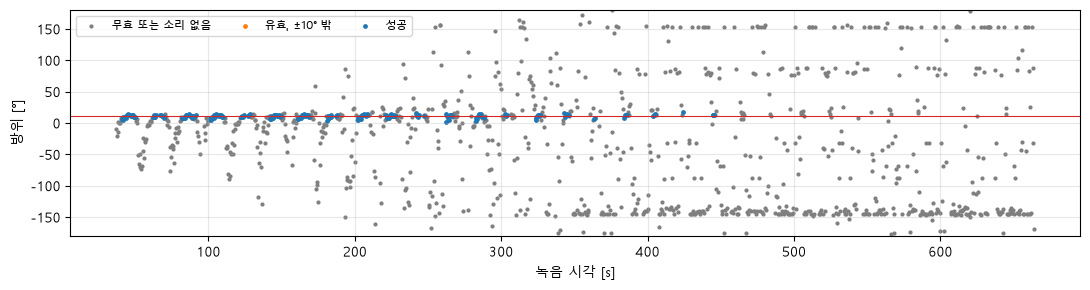

In [8]:
def circ_median(a):
    a = np.asarray(a); return float(a[np.argmin([np.sum(np.abs((a - v + 180) % 360 - 180)) for v in a])])
if MODE == "실측" and os.path.exists(f"{REC}/doa_mcu.csv"):
    rows = list(csv.DictReader(open(f"{REC}/doa_mcu.csv")))
    R = [dict(t=(int(r["s0"]) - START) / FS, valid=bool(int(r["flags"]) & F_VALID), present=bool(int(r["flags"]) & F_PRESENT),
              angle=float(r["angle"])) for r in rows if not int(r["flags"]) & F_LEARN]
    DOA_SRC = "보드 doa_mcu.csv"
else:
    ap = argparse.ArgumentParser(); ds.add_args(ap); A = ap.parse_args(["--hop", "0.5"])
    res = ds.run(X, FS, A, 0, bg=ds.background(X, FS, A, seconds=10.0))
    R = [dict(t=r["s0"] / FS, valid=r["valid"], present=r["present"], angle=r["angle"]) for r in res]
    DOA_SRC = "PC 기준 구현 doa_stream.run"
D = []
for r in R:
    k = int((r["t"] - P0 - LEAD) // STEP_S)
    if 0 <= k < N_STEP:
        a0 = P0 + LEAD + STEP_S * k
        if a0 + 1.0 <= r["t"] and r["t"] + 0.5 <= a0 + STEP_S - 1.0: D.append((k, r["t"], snr_db(r["t"], r["t"] + 0.5), r["valid"] and r["present"], r["angle"]))
D_K = np.array([d[0] for d in D]); D_T = np.array([d[1] for d in D]); D_SNR = np.array([d[2] for d in D])
D_VP = np.array([d[3] for d in D]); D_ANG = np.array([d[4] for d in D])
ref_m = D_VP & (D_K <= 2)
REF = circ_median(D_ANG[ref_m])
D_OK = D_VP & (np.abs((D_ANG - REF + 180) % 360 - 180) <= DOA_TOL)
print(f"방향 출처: {DOA_SRC} · 창 {len(D)}개 · 기준 방위 {REF:.1f}° (0 ~ −4 dB 단계의 유효 {ref_m.sum()}개 / {(D_K <= 2).sum()}개)")
fig, ax = plt.subplots(figsize=(11, 3))
ax.scatter(D_T[~D_VP], D_ANG[~D_VP], s=4, c="C7", label="무효 또는 소리 없음")
ax.scatter(D_T[D_VP & ~D_OK], D_ANG[D_VP & ~D_OK], s=6, c="C1", label=f"유효, ±{DOA_TOL:.0f}° 밖")
ax.scatter(D_T[D_OK], D_ANG[D_OK], s=6, c="C0", label="성공")
ax.axhline(REF, color="C3", lw=.8); ax.set_ylim(-180, 180); ax.set_xlabel("녹음 시각 [s]"); ax.set_ylabel("방위 [°]")
ax.legend(fontsize=8, ncol=3); ax.grid(alpha=.3); plt.tight_layout(); plt.show()

## 7. 성공률 — SNR 곡선

▶ 예측 지점 (T1)

창을 SNR 2 dB 칸으로 묶어 칸마다 성공률을 낸다 (창이 10개 미만인 칸은 뺀다). 칸 사이 출렁임은 **아래에서 위로 오를수록 줄지 않게** 고친다 (단조 회귀, PAVA). 50 %·90 %에 처음 닿는 SNR을 칸 사이 직선 보간으로 찾는다. 성공률이 그 수준에 닿지 않으면 "도달 못 함"이다.

구간: 단계마다 창을 복원 추출(같은 수)해 200번 다시 계산한 2.5 ~ 97.5 %. "도달 못 함"이 나온 횟수도 센다.

**0 → 100 %로 오르는 S자 곡선(로지스틱)을 맞추지 않는 이유:** B0는 조용한 창에서도 5절의 비율만큼 성공해 바닥이 0이 아니고, 방향은 높은 SNR에서도 100 %에 닿지 않을 수 있다. S자 곡선은 이 둘을 무시하고 50·90 %를 억지로 만든다.

B0 판정 50 %:  -3.3 dB  [-5.2, -1.8] 절반 폭 1.7 dB  (재추출 중 도달 못 함 0%)


B0 판정 90 %:   4.5 dB  [0.9, 7.4] 절반 폭 3.2 dB  (재추출 중 도달 못 함 0%)
방향 50 %:  13.3 dB  [12.1, 14.1] 절반 폭 1.0 dB  (재추출 중 도달 못 함 0%)


방향 90 %:  23.4 dB  [20.5, 24.3] 절반 폭 1.9 dB  (재추출 중 도달 못 함 0%)


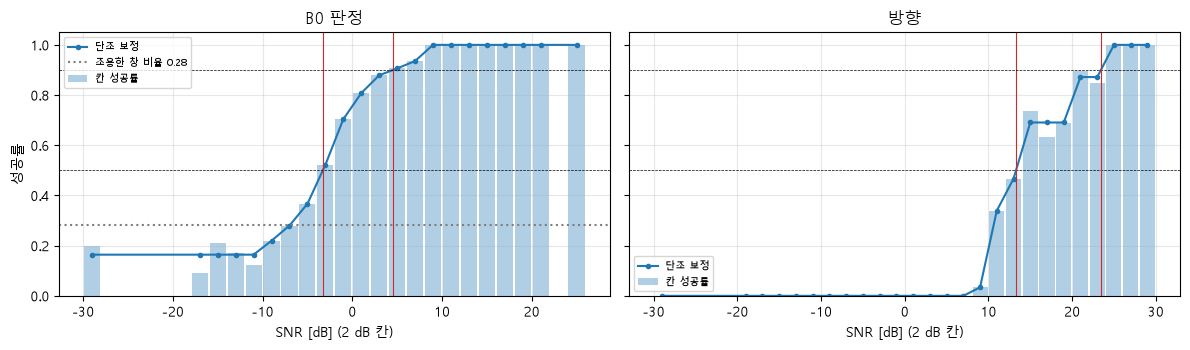


칸별 표 (B0):
  SNR 칸    -29   -17   -15   -13   -11    -9    -7    -5    -3    -1     1     3     5     7     9    11    13    15    17    19    21    25
  창 수      30    11    19    35    33    41    25    30    23    27    26    33    32    31    27    32    22    20    16    14    11    10
  성공률   0.20  0.09  0.21  0.17  0.12  0.22  0.28  0.37  0.52  0.70  0.81  0.88  0.91  0.94  1.00  1.00  1.00  1.00  1.00  1.00  1.00  1.00


In [9]:
def pava(y, w):
    y, w = list(map(float, y)), list(map(float, w)); blocks = [[y[i], w[i], 1] for i in range(len(y))]
    i = 0
    while i < len(blocks) - 1:
        if blocks[i][0] > blocks[i + 1][0]:
            a, b = blocks[i], blocks[i + 1]; ww = a[1] + b[1]
            blocks[i] = [(a[0] * a[1] + b[0] * b[1]) / ww, ww, a[2] + b[2]]; del blocks[i + 1]; i = max(i - 1, 0)
        else: i += 1
    return np.concatenate([[v] * n for v, _, n in blocks])
def curve(snr, ok, min_n=10):
    lo = 2 * np.floor(snr.min() / 2); edges = np.arange(lo, snr.max() + 2, 2.0)
    c, r, n = [], [], []
    for a in edges[:-1]:
        m = (snr >= a) & (snr < a + 2)
        if m.sum() >= min_n: c.append(a + 1); r.append(ok[m].mean()); n.append(m.sum())
    c, r, n = map(np.array, (c, r, n)); return c, r, n, pava(r, n)
def cross(c, iso, level):
    if iso.max() < level: return None
    i = int(np.argmax(iso >= level))
    if i == 0: return float(c[0])
    return float(c[i - 1] + (level - iso[i - 1]) / (iso[i] - iso[i - 1] + 1e-12) * (c[i] - c[i - 1]))
def boot(snr, ok, step, level, n=200, seed=0):
    rng = np.random.default_rng(seed); v, none = [], 0
    for _ in range(n):
        idx = np.concatenate([rng.choice(np.where(step == k)[0], (step == k).sum()) for k in np.unique(step)])
        c, r, nn, iso = curve(snr[idx], ok[idx]); x = cross(c, iso, level)
        if x is None: none += 1
        else: v.append(x)
    return (np.percentile(v, [2.5, 97.5]) if v else (np.nan, np.nan)), none / n
RES = {}
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for j, (name, snr, ok, step) in enumerate([("B0 판정", B0_SNR, B0_OK, B0_K), ("방향", D_SNR, D_OK, D_K)]):
    c, r, n, iso = curve(snr, ok)
    ax[j].bar(c, r, width=1.8, alpha=.35, label="칸 성공률"); ax[j].plot(c, iso, "o-", ms=3, label="단조 보정")
    if name == "B0 판정": ax[j].axhline(Q_RATE, color="C7", ls=":", label=f"조용한 창 비율 {Q_RATE:.2f}")
    for lv in (.5, .9):
        x = cross(c, iso, lv); (lo, hi), fn = boot(snr, ok, step, lv)
        RES[(name, lv)] = dict(x=x, lo=lo, hi=hi, none=fn)
        ax[j].axhline(lv, color="k", lw=.5, ls="--")
        if x is not None: ax[j].axvline(x, color="C3", lw=.8)
        print(f"{name} {int(lv * 100)} %: " + (f"{x:5.1f} dB  [{lo:.1f}, {hi:.1f}] 절반 폭 {(hi - lo) / 2:.1f} dB" if x is not None else "도달 못 함") + f"  (재추출 중 도달 못 함 {fn:.0%})")
    ax[j].set_title(name); ax[j].set_xlabel("SNR [dB] (2 dB 칸)"); ax[j].grid(alpha=.3); ax[j].legend(fontsize=7)
ax[0].set_ylabel("성공률"); plt.tight_layout(); plt.show()
print("\n칸별 표 (B0):"); c, r, n, iso = curve(B0_SNR, B0_OK)
print("  SNR 칸  " + " ".join(f"{v:5.0f}" for v in c)); print("  창 수   " + " ".join(f"{v:5d}" for v in n)); print("  성공률  " + " ".join(f"{v:5.2f}" for v in r))

## 8. 발견

리허설(2026-10-28)에서 실제 측정 전에 알아야 할 것이 두 가지 나왔다.

1. **B0는 드론이 없어도 보드 잡음에서 문턱을 넘는다.** 5절의 조용한 창 비율, 그리고 따로 잰 `quiet_10min` 전체(1 s 창 595개)에서 25 %가 13.1을 넘었고 기본음은 44 ~ 50 Hz였다. 3절 스펙트럼의 48.8 Hz 배수 줄(프레임 주기 빗)을 40 ~ 700 Hz 후보의 낮은 끝이 고조파로 본 것으로 추정한다. 그래서 B0 성공률은 0까지 내려가지 않고, 측정 전에 정한 "≥ 13.1이면 성공" 정의 그대로면 50 % SNR이 실제보다 낮게(좋게) 나온다.
2. **단계로 묶으면 안 되고 창 SNR로 묶어야 한다.** 리허설의 0 ~ −4 dB 단계에서 방향 성공(유효·±10°)은 절반 안팎(6절)이지만, 같은 창들을 SNR로 묶으면 높은 SNR 칸은 90 %에 닿는다(7절). FPV 원음이 30 s 안에서 크게 출렁여(통과 비행) 같은 단계 안에도 낮은 SNR 창이 많기 때문이다. 측정 전에 정한 "창마다 SNR을 재서 묶는다"가 필요한 이유가 리허설에서 확인됐다. 다만 실제 0.5 m 재생에서 방향 90 %에 닿을지는 모른다 — FPV처럼 고조파 몇 줄에 몰린 소리는 PHAT 봉우리가 낮아질 수 있다 (`doa_mask_phat.ipynb` 4·5절).
3. **측정 절차 위험 (리허설 밖, 파일 확인):** `51_T_fpv_steps.wav`·`52_T_mini3_steps.wav`는 **모노**라 노트북 스피커 두 개(좌우 약 30 cm)에서 같이 나온다. 0.5 m에서 두 스피커는 배열에서 약 33° 벌어져 보인다 (2 × atan(0.15 ÷ 0.5)). Step7에서 같은 이유로 FPV 유효율이 55 ~ 66 %에 그쳐 왼쪽 채널만 있는 파일(`21_doa_left_100s.wav`)로 바꿨다. 이대로 녹음하면 방향 T는 SNR이 아니라 두 스피커 때문에 무너질 수 있다.

## 9. 결론 후보 (사용자 확인 전)

아래 셀이 위 결과에서 숫자를 다시 뽑는다.

In [10]:
print(f"모드: {MODE} · 재생 시작 {P0:.2f} s · 바닥 {10 * np.log10(2 * P_FL / 32768 ** 2):.1f} dBFS · 조용한 창 B0 비율 {Q_RATE:.2f} · 방향 출처 {DOA_SRC}")
for (name, lv), v in RES.items():
    ok = v["x"] is not None and (v["hi"] - v["lo"]) / 2 <= 2.0
    print(f"  {name} {int(lv * 100)} %: " + (f"{v['x']:.1f} dB [{v['lo']:.1f}, {v['hi']:.1f}]" if v["x"] is not None else "도달 못 함")
          + f" → 통과 기준(±2 dB) {'충족' if ok else '미충족'}")
if MODE == "리허설":
    print("\n리허설: 위 숫자는 T가 아니다 (재료가 실제 측정과 다르다). 흐름 확인 결과만 쓴다.")
    print(f"  재생 시작을 넣은 값 {P0_TRUE} s에서 {P0 - P0_TRUE:+.2f} s 차이로 되찾음")

모드: 리허설 · 재생 시작 15.55 s · 바닥 -63.5 dBFS · 조용한 창 B0 비율 0.28 · 방향 출처 PC 기준 구현 doa_stream.run
  B0 판정 50 %: -3.3 dB [-5.2, -1.8] → 통과 기준(±2 dB) 충족
  B0 판정 90 %: 4.5 dB [0.9, 7.4] → 통과 기준(±2 dB) 미충족
  방향 50 %: 13.3 dB [12.1, 14.1] → 통과 기준(±2 dB) 충족
  방향 90 %: 23.4 dB [20.5, 24.3] → 통과 기준(±2 dB) 충족

리허설: 위 숫자는 T가 아니다 (재료가 실제 측정과 다르다). 흐름 확인 결과만 쓴다.
  재생 시작을 넣은 값 15.0 s에서 +0.55 s 차이로 되찾음


**후보 (리허설, 2026-10-28)**
1. 분석 흐름은 실제 측정 녹음에 그대로 쓸 수 있다 — 재생 시작을 되찾고, 창 SNR·B0·방향·칸 성공률·구간까지 끝까지 돈다 (2·7·9절). 모르는 것: 실제 녹음의 SNR 범위(0.5 m 재생이라 리허설보다 높을 것).
2. **녹음 전에:** 재생 파일을 왼쪽 채널만 있는 스테레오로 바꾼다 (8절 3). 모르는 것: 왼쪽 스피커 하나의 음량이 보드 눈금 때와 달라지는 영향 — SNR은 창마다 재므로 T에는 영향이 작을 것 (`추정`).
3. **B0 성공 정의:** 측정 전에 고정한 정의(≥ 13.1)를 유지하되 조용한 창 비율을 함께 적을지, 또는 기본음이 48.8 Hz 배수 근처인 창을 뺄지는 사용자가 정한다 (8절 1). 모르는 것: 실제 측정 날 보드 빗의 크기.
4. 실측에서 어느 판정이든 90 %가 "도달 못 함"으로 나오면, 그 T는 50 %만 쓰고 최대 성공률을 따로 적는다 (7절 처리 규칙).
5. 재생 시작 되찾기 오차는 리허설에서 +0.55 s였다 — 리허설 재료가 재생 파일과 내용이 달라서다. 단계 경계 앞뒤 1 s를 빼므로 결과에는 영향이 없다 (2절). 실측은 내용이 같아 더 정확할 것 (`추정`).